# 03. KB và RAG cho báo cáo tài chính/chứng khoán
Thực nghiệm toàn bộ 883 câu hỏi FinQA dev: BM25 dòng thô, BM25 có header, dense và hybrid; mỗi phương án global/oracle-report. Sinh thật trên mẫu 24 câu chọn bằng seed 42.

Train/test được tải đầy đủ nhưng không huấn luyện hoặc tối ưu trên test. Không đưa `answer`, `program`, `exe_ans`, `gold_inds`, `model_input` vào corpus. Báo cáo rõ corpus dev khép kín, lọc báo cáo oracle, giới hạn mẫu generation và không suy diễn thành hiệu quả giao dịch.

In [1]:
from pathlib import Path
import sys, json, time, random, platform, importlib.metadata as metadata
ROOT = Path.cwd().resolve()
while not (ROOT / 'data/chapter04').exists():
    if ROOT.parent == ROOT: raise RuntimeError('Không tìm thấy thư mục dự án')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data/chapter04'
RESULT = ROOT / 'results/chapter04'
FIG = ROOT / 'docs/report_chapter_04'
RESULT.mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
random.seed(42); np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
environment = {'python': platform.python_version(), 'platform': platform.platform(),
    'packages': {p: metadata.version(p) for p in ['numpy','pandas','networkx','torch','transformers','nbclient','fastapi']}}
display(pd.DataFrame(environment['packages'].items(), columns=['Thư viện','Phiên bản']))

,Thư viện,Phiên bản
0,numpy,2.5.2
1,pandas,3.0.5
2,networkx,3.6.1
3,torch,2.13.0
4,transformers,4.57.6
5,nbclient,0.11.0
6,fastapi,0.141.1


## 1. Corpus, bằng chứng và phép biến đổi bảng

In [2]:
from src.chapter04.retrieval import BM25,Encoder,DenseRetriever,build_finance_chunks,report_key,hybrid_search,retrieval_metrics
items=json.loads((DATA/'finqa_dev.json').read_text(encoding='utf-8'))
raw_chunks=build_finance_chunks(items,table_headers=False)
chunks=build_finance_chunks(items,table_headers=True)
lookup={x['id']:x for x in chunks}
golds=[{report_key(item)+'::'+key for key in item['qa']['gold_inds']} for item in items]
assert all(g and g.issubset(lookup) for g in golds)
report_allowed={r:{x['id'] for x in chunks if x['report']==r} for r in {x['report'] for x in chunks}}
display(pd.DataFrame([x for x in chunks if x['kind']=='table'][:5])[['key','text','filename']])
print('Questions:',len(items),'Chunks:',len(chunks),'Report contexts:',len(report_allowed))

,key,text,filename
0,table_0,company | payments volume ( billions ) | total...,V/2008/page_17.pdf
1,table_1,company: visa inc. ( 1 ) ; payments volume ( b...,V/2008/page_17.pdf
2,table_2,company: mastercard ; payments volume ( billio...,V/2008/page_17.pdf
3,table_3,company: american express ; payments volume ( ...,V/2008/page_17.pdf
4,table_4,company: discover ; payments volume ( billions...,V/2008/page_17.pdf


Questions: 883 Chunks: 9177 Report contexts: 299


## 2. Truy hồi pretrained dense và baseline từ khóa

In [3]:
encoder=Encoder(ROOT/'models/chapter04/embedding')
raw_bm25=BM25(raw_chunks);bm25=BM25(chunks)
dense=DenseRetriever(chunks,encoder,RESULT/'finance_embeddings.npy')
queries=[x['qa']['question'] for x in items]
qvec=encoder.encode(queries)
print('Document vectors:',dense.vectors.shape,'; Query vectors:',qvec.shape)

Document vectors: (9177, 384) ; Query vectors: (883, 384)


## 3. Chạy 8 cấu hình trên đủ 883 câu hỏi

In [4]:
records=[]; ranked_by_mode={}
for method in ['bm25_raw','bm25_headers','dense','hybrid']:
    for scope in ['global','oracle_report']:
        started=time.perf_counter();ranks=[]
        for i,item in enumerate(items):
            allowed=report_allowed[report_key(item)] if scope=='oracle_report' else None
            if method=='bm25_raw': hits=raw_bm25.search(queries[i],5,allowed)
            elif method=='bm25_headers': hits=bm25.search(queries[i],5,allowed)
            elif method=='dense': hits=dense.search(queries[i],5,allowed,qvec[i])
            else: hits=hybrid_search(bm25,dense,queries[i],5,allowed,qvec[i])
            ranks.append([x['id'] for x in hits])
        metric=retrieval_metrics(ranks,golds);metric.update(method=method,scope=scope,seconds=time.perf_counter()-started)
        records.append(metric);ranked_by_mode[method+'_'+scope]=ranks
        print(method,scope,'Hit@5',round(metric['hit_at_5'],4),flush=True)
metrics=pd.DataFrame(records)
display(metrics.round(4))
metrics.to_csv(RESULT/'finance_retrieval_metrics.csv',index=False,encoding='utf-8-sig')

bm25_raw global Hit@5 0.5198


bm25_raw oracle_report Hit@5 0.8097


bm25_headers global Hit@5 0.6195


bm25_headers oracle_report Hit@5 0.8947


dense global Hit@5 0.6217


dense oracle_report Hit@5 0.9139


hybrid global Hit@5 0.6829


hybrid oracle_report Hit@5 0.9264


,questions,hit_at_1,hit_at_5,recall_at_5,mrr_at_5,complete_at_5,method,scope,seconds
0,883,0.3239,0.5198,0.4034,0.3976,0.3058,bm25_raw,global,40.8613
1,883,0.4926,0.8097,0.6769,0.6090,0.5527,bm25_raw,oracle_report,9.1998
2,883,0.4100,0.6195,0.5094,0.4903,0.4088,bm25_headers,global,40.6220
3,883,0.5878,0.8947,0.7838,0.7062,0.6738,bm25_headers,oracle_report,9.7397
4,883,0.4236,0.6217,0.5050,0.5013,0.3952,dense,global,22.2317
5,883,0.6217,0.9139,0.7980,0.7398,0.6716,dense,oracle_report,4.4058
6,883,0.4462,0.6829,0.5607,0.5349,0.4485,hybrid,global,63.8797
7,883,0.6308,0.9264,0.8200,0.7511,0.7055,hybrid,oracle_report,13.9041


## 4. Sinh và chấm câu trả lời số trên mẫu cố định

In [5]:
from src.chapter04.rag import LocalGenerator
from src.chapter04.evaluation import parse_numeric_answer, numeric_answer_matches, gold_execution_consistency
import re,math
generator=LocalGenerator(ROOT/'models/chapter04/generator')
selected=sorted(random.Random(42).sample(range(len(items)),24))
outputs=[]
def numeric_value(text):
    parsed=parse_numeric_answer(text)
    return parsed['value'] if parsed else None
for i in selected:
    item=items[i];reference=str(item['qa']['answer']);exe_reference=float(item['qa']['exe_ans'])
    for mode in ['no_context','hybrid_rag_oracle_report','gold_context_oracle']:
        ids=[] if mode=='no_context' else ranked_by_mode['hybrid_oracle_report'][i][:3] if mode=='hybrid_rag_oracle_report' else sorted(golds[i])
        evidence=None if mode=='no_context' else [lookup[cid] for cid in ids]
        started=time.perf_counter();answer=generator.generate(queries[i],evidence);number=numeric_value(answer)
        outputs.append({'id':item['id'],'mode':mode,'question':queries[i],'answer':answer,'reference':reference,'exe_ans':exe_reference,
            'numeric_prediction':number,'numeric_accuracy':numeric_answer_matches(answer,reference),
            'gold_execution_consistent':gold_execution_consistency(reference,exe_reference),
            'evidence_ids':ids,'seconds':time.perf_counter()-started})
generation=pd.DataFrame(outputs)
gen_metrics=generation.groupby('mode').agg(questions=('id','size'),numeric_accuracy=('numeric_accuracy','mean'),mean_seconds=('seconds','mean')).reset_index()
display(gen_metrics.round(4));display(generation[['id','mode','answer','reference','numeric_accuracy']].head(12))
gold_audit=generation[generation['mode']=='no_context'][['id','reference','exe_ans','gold_execution_consistent']].copy()
display(gold_audit[~gold_audit['gold_execution_consistent']])
gold_audit.to_csv(RESULT/'finance_gold_audit.csv',index=False,encoding='utf-8-sig')
generation.to_csv(RESULT/'finance_generation_predictions.csv',index=False,encoding='utf-8-sig')

,mode,questions,numeric_accuracy,mean_seconds
0,gold_context_oracle,24,0.0,0.4443
1,hybrid_rag_oracle_report,24,0.0,0.5591
2,no_context,24,0.0,0.6097


,id,mode,answer,reference,numeric_accuracy
0,PNC/2009/page_46.pdf-2,no_context,0.8,-1,False
1,PNC/2009/page_46.pdf-2,hybrid_rag_oracle_report,0,-1,False
2,PNC/2009/page_46.pdf-2,gold_context_oracle,3,-1,False
3,HOLX/2015/page_98.pdf-2,no_context,4.5%,-3.0%,False
4,HOLX/2015/page_98.pdf-2,hybrid_rag_oracle_report,377.0: $ 365.6,-3.0%,False
5,HOLX/2015/page_98.pdf-2,gold_context_oracle,365.6,-3.0%,False
6,AES/2016/page_191.pdf-3,no_context,a total of .,11.3,False
7,AES/2016/page_191.pdf-3,hybrid_rag_oracle_report,$ 32 million,11.3,False
8,AES/2016/page_191.pdf-3,gold_context_oracle,2,11.3,False
9,MAS/2012/page_70.pdf-1,no_context,5%,-21%,False


,id,reference,exe_ans,gold_execution_consistent
6,AES/2016/page_191.pdf-3,11.3,-11.33333,False
9,MAS/2012/page_70.pdf-1,-21%,-0.20646,False
27,MSI/2006/page_61.pdf-4,232,349.50000,False
30,BDX/2019/page_45.pdf-1,44.4%,-44.60000,False
57,AON/2014/page_47.pdf-2,360,3.60000,False
69,JPM/2007/page_147.pdf-1,2.1%,20460.00000,False


## 5. Công cụ tính toán trên số liệu thật, không lấy program chuẩn làm dự đoán

In [6]:
from src.chapter04.knowledge import safe_calculate
example=items[0]
# Inspect the actual source table, then select cells by company/column names.
table=pd.DataFrame(example['table'][1:],columns=example['table'][0])
display(table)
row=table[table.iloc[:,0].str.contains('american express')].iloc[0]
volume=float(re.sub(r'[^0-9.]','',row.iloc[1]));transactions=float(re.sub(r'[^0-9.]','',row.iloc[3]))
calculated=safe_calculate('divide',[volume,transactions])
print('Retrieved table calculation:',calculated)
print('Operands manually mapped from source table; not automatic end-to-end FinQA program inference.')
assert math.isclose(calculated['value'],127.4)

,company,payments volume ( billions ),total volume ( billions ),total transactions ( billions ),cards ( millions )
0,visa inc. ( 1 ),$ 2457,$ 3822,50.3,1592
1,mastercard,1697,2276,27.0,916
2,american express,637,647,5.0,86
3,discover,102,119,1.6,57
4,jcb,55,61,0.6,58
5,diners club,29,30,0.2,7


Retrieved table calculation: {'value': 127.4, 'formula': '637.0 / 5.0', 'unit': 'unspecified'}
Operands manually mapped from source table; not automatic end-to-end FinQA program inference.


## 6. Biểu đồ và lưu kết quả đầy đủ

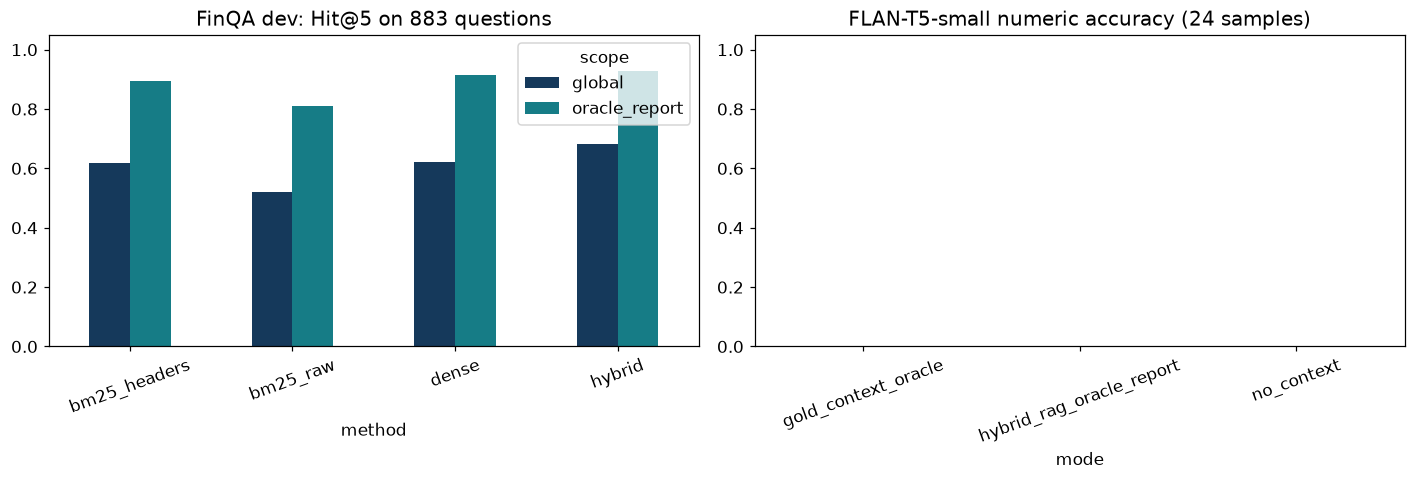

1636379

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
metrics.pivot(index='method',columns='scope',values='hit_at_5').plot.bar(ax=axes[0],ylim=(0,1.05),color=['#15395B','#167C86'])
axes[0].set_title('FinQA dev: Hit@5 on 883 questions');axes[0].tick_params(axis='x',rotation=20)
gen_metrics.set_index('mode')['numeric_accuracy'].plot.bar(ax=axes[1],ylim=(0,1.05),color='#167C86')
axes[1].set_title('FLAN-T5-small numeric accuracy (24 samples)');axes[1].tick_params(axis='x',rotation=20)
fig.tight_layout();fig.savefig(FIG/'finance_rag_extended.png',bbox_inches='tight');plt.show()
result={'retrieval':records,'generation':gen_metrics.to_dict('records'),'generation_sample_size':24,
        'generation_sample_indices':selected,'generation_outputs':outputs,'gold_audit':gold_audit.to_dict('records'),'questions':len(items),
        'chunks':len(chunks),'reports':len(report_allowed),'calculator_example':calculated,'environment':environment,
        'limitations':['oracle report filter','closed dev corpus','English','small generation sample','no trading validation']}
(RESULT/'finance_rag_results.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
(RESULT/'finance_rankings.json').write_text(json.dumps(ranked_by_mode),encoding='utf-8')

## Nhận xét
Truy hồi đúng không đảm bảo mô hình nhỏ tính đúng. Numeric accuracy đo khớp qa.answer theo đơn vị hiển thị, dùng rel_tol=0,001 và abs_tol=0,01. Nếu chuẩn có '%' và model không ghi đơn vị thì diễn giải theo đơn vị chuẩn; '%' tường minh khi chuẩn là ratio được đổi về fraction. Audit qa.answer/exe_ans lưu riêng do một số nhãn chuẩn không nhất quán. Calculator chọn ô thủ công, không tính như bộ giải toàn FinQA.